# 06 Slantsy scenarios

This notebook estimates yearly visitors for the planned Research Institute and Museum of Geology in Slantsy, using the model calibrated in 05 (model C: location + heritage class).

**Location.** The new complex is on the Plyussa riverfront in the town centre, a short distance from the existing Slantsy museum, so the existing museum's travel times are used for it.

**Distance decay range.** The model is run at the central β and at the lowest and highest β from leave-one-out. For each β, k and the heritage effect are refitted on the 8 sites.

**What is modelled and what is added.** The gravity model covers day trips by car from St Petersburg, Leningrad Oblast and the border areas. Visitors to the research institute itself (conferences, student field groups, partner researchers) and long-distance tourists are not driven by population and distance, so they are added later as separate lines.

**Benchmark.** The closest real analogue is the Messel Pit in Germany (UNESCO fossil site in a former oil shale mine, with research on site and a visitor centre opened in 2010): about 30,000 visitors in 2023 and over 40,000 in 2025, against an original expectation of 100,000.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

PROCESSED = "../data/processed"

origins = pd.read_csv(f"{PROCESSED}/origins.csv")
tt = pd.read_csv(f"{PROCESSED}/travel_times.csv").set_index("origin_id")
pop = origins.set_index("origin_id")["population"].reindex(tt.index)
P = pop.to_numpy()
params = pd.read_csv(f"{PROCESSED}/calibration_params.csv").set_index("model")
sites = pd.read_csv(f"{PROCESSED}/calibration_sites.csv", index_col="name_en")

# new complex: same town centre as the existing museum, so same travel times
NEW_SITE_PROXY = "Slantsy Local History Museum"
t_new = tt[[NEW_SITE_PROXY]].to_numpy()

T_cal = tt[sites.index].to_numpy()
y = np.log(sites["visitors"].to_numpy())
h = sites["heritage"].to_numpy().astype(float)

def log_access(beta, T):
    # log of sum_i P_i * exp(-beta * t_ij)
    return logsumexp(-beta * T, b=P[:, None], axis=0)

def fit_fixed_beta(beta):
    # with β fixed, log k and γ come from an ordinary linear regression
    X = np.column_stack([np.ones_like(h), h])
    coef, *_ = np.linalg.lstsq(X, y - log_access(beta, T_cal), rcond=None)
    return coef   # log_k, gamma

c = params.loc["C"]
rows = []
for label, b in [("slow decay (β low)", c["beta_low"]),
                 ("central", c["beta"]),
                 ("fast decay (β high)", c["beta_high"])]:
    lk, g = fit_fixed_beta(b)
    acc = log_access(b, t_new)[0]
    rows.append({"case": label, "beta": b, "halves_min": np.log(2) / b,
                 "heritage_x": np.exp(g),
                 "local_class": np.exp(lk + acc),
                 "heritage_class": np.exp(lk + g + acc)})
slantsy = pd.DataFrame(rows).set_index("case")

# check: the central row should match model C from 05
lk_c, g_c = fit_fixed_beta(c["beta"])
print(f"Check vs 05: log_k {lk_c:.4f} vs {c['log_k']:.4f}, gamma {g_c:.4f} vs {c['gamma']:.4f}")
slantsy.round({"beta": 4, "halves_min": 0, "heritage_x": 1, "local_class": 0, "heritage_class": 0})

Check vs 05: log_k -4.8241 vs -4.8241, gamma 2.1241 vs 2.1241


,beta,halves_min,heritage_x,local_class,heritage_class
case,,,,,
slow decay (β low),0.0120,58.0,8.6,4998.0,43031.0
central,0.0158,44.0,8.4,4305.0,36015.0
fast decay (β high),0.0189,37.0,8.2,3874.0,31800.0


## Scenarios

The new complex is treated as a **heritage-class** attraction: a purpose-built museum with research on site, an observation tower on the spoil heap and the Klint nearby, rather than a local history museum. How strongly it performs within that class is the main uncertainty, so the scenarios use the real spread of the four heritage sites:

- **Low:** performs like the weakest heritage site relative to its location.
- **Base:** a typical heritage site.
- **High:** performs like the strongest heritage site.

Each scenario is computed for the three distance-decay cases. The local-museum level is shown only as a reference: it is what the existing Slantsy museum already achieves.

In [2]:
# low / base / high for each decay case
heritage_names = sites.index[h == 1]
grid = []
for case, row in slantsy.iterrows():
    lk, g = fit_fixed_beta(row["beta"])
    pred_sites = np.exp(lk + g * h + log_access(row["beta"], T_cal))
    factor = sites["visitors"].to_numpy() / pred_sites
    fh = factor[h == 1]
    grid.append({"case": case,
                 "weakest": heritage_names[fh.argmin()], "f_low": fh.min(),
                 "strongest": heritage_names[fh.argmax()], "f_high": fh.max(),
                 "low": row["heritage_class"] * fh.min(),
                 "base": row["heritage_class"],
                 "high": row["heritage_class"] * fh.max()})
grid = pd.DataFrame(grid).set_index("case")

cen = grid.loc["central"]
print(f"Day trips by car, central decay: low {cen['low']:,.0f}, base {cen['base']:,.0f}, high {cen['high']:,.0f}")
print(f"Including decay range: {grid['low'].min():,.0f} to {grid['high'].max():,.0f}")
grid.round({"f_low": 2, "f_high": 2, "low": 0, "base": 0, "high": 0})

Day trips by car, central decay: low 19,113, base 36,015, high 64,791
Including decay range: 16,811 to 75,658


,weakest,f_low,strongest,f_high,low,base,high
case,,,,,,,
slow decay (β low),Koporye Fortress,0.53,Staraya Ladoga Museum-Reserve,1.76,23016.0,43031.0,75658.0
central,Koporye Fortress,0.53,Staraya Ladoga Museum-Reserve,1.80,19113.0,36015.0,64791.0
fast decay (β high),Koporye Fortress,0.53,Staraya Ladoga Museum-Reserve,1.83,16811.0,31800.0,58229.0


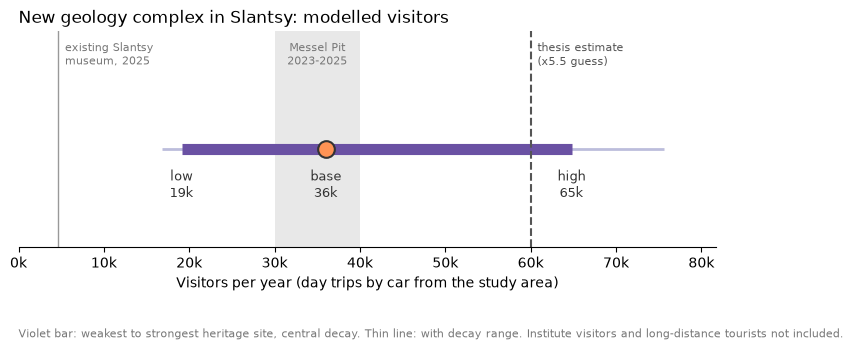

In [11]:
# summary chart
from matplotlib.ticker import FuncFormatter

lo_all, hi_all = grid["low"].min(), grid["high"].max()

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.axvspan(30000, 40000, color="#d9d9d9", alpha=0.6, lw=0)   # Messel 2023-2025
ax.hlines(1, lo_all, hi_all, color="#bcbddc", lw=2)          # decay range
ax.hlines(1, cen["low"], cen["high"], color="#6a51a3", lw=8)  # low to high, central decay
ax.plot(cen["base"], 1, "o", ms=12, color="#FF9354", mec="#333333", mew=1.5, zorder=3)
for x, txt in [(cen["low"], "low"), (cen["base"], "base"), (cen["high"], "high")]:
    ax.annotate(f"{txt}\n{x / 1000:.0f}k", (x, 1), xytext=(0, -14), textcoords="offset points",
                ha="center", va="top", fontsize=9, color="#333333")

ax.axvline(4645, color="#999999", lw=1)
ax.axvline(60000, color="#555555", lw=1.5, ls="--")
ax.text(4645 + 800, 1.55, "existing Slantsy\nmuseum, 2025", ha="left", va="top", fontsize=8, color="#777777")
ax.text(35000, 1.55, "Messel Pit\n2023-2025", ha="center", va="top", fontsize=8, color="#777777")
ax.text(60000 + 800, 1.55, "thesis estimate\n(x5.5 guess)", ha="left", va="top", fontsize=8, color="#555555")

ax.set_ylim(0.5, 1.6)
ax.set_xlim(0, hi_all * 1.08)
ax.set_yticks([])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:g}k"))
ax.set_xlabel("Visitors per year (day trips by car from the study area)")
ax.set_title("New geology complex in Slantsy: modelled visitors", loc="left")
ax.text(0, -0.42, "Violet bar: weakest to strongest heritage site, central decay. Thin line: with decay range. "
        "Institute visitors and long-distance tourists not included.",
        transform=ax.transAxes, fontsize=8, color="#777777")
for s in ["left", "top", "right"]:
    ax.spines[s].set_visible(False)
fig.savefig("../figures/06_scenarios.png", dpi=200, bbox_inches="tight")
plt.show()

## Add-on lines and export

Visitors who do not follow population and distance are added as separate lines with rough low/base/high estimates, in two groups:

- **museum** (paying visitors): day trips from the model, plus long-distance tourists as a share of day trips.
- **institute** (person-days on site per year): events, university and college field groups, visiting researchers and interns. St Petersburg is about 3 hours away by car, so researchers and interns come for several days at a time rather than commuting daily. They do not buy museum tickets but need accommodation in Slantsy.

School groups are already part of museum attendance; staff are not visitors. Values use the central decay and are exported to `data/processed/visitors_range.csv` for the feasibility model (Project 5), which uses the museum total as `visitors_per_year`.

In [6]:
# add-on lines (rough estimates, to review) and export
# institute lines are person-days on site per year
INSTITUTE = {
    "institute_events":     {"low": 4 * 40,  "base": 10 * 60, "high": 20 * 80},  # events x guests
    "student_field_groups": {"low": 10 * 15, "base": 25 * 20, "high": 50 * 25},  # groups x size
    "visiting_researchers": {"low": 20 * 10, "base": 40 * 15, "high": 75 * 20},  # people x days
    "interns":              {"low": 10 * 20, "base": 30 * 20, "high": 60 * 20},  # interns x working days
}
TOURIST_SHARE = {"low": 0.0, "base": 0.10, "high": 0.20}   # long-distance tourists, share of day trips

day = grid.loc["central", ["low", "base", "high"]]
museum = pd.DataFrame([
    {"component": "day_trips_model", **day.to_dict()},
    {"component": "long_distance_tourists", **{s: day[s] * TOURIST_SHARE[s] for s in day.index}},
]).set_index("component")
museum.loc["museum_total"] = museum.sum()

institute = pd.DataFrame([{"component": k, **v} for k, v in INSTITUTE.items()]).set_index("component")
institute.loc["institute_total"] = institute.sum()

out = pd.concat({"museum": museum, "institute": institute}, names=["group", "component"])
out = out.round(0).astype(int)
out.to_csv(f"{PROCESSED}/visitors_range.csv")
out

low   base   high
group     component                                  
museum    day_trips_model         19113  36015  64791
          long_distance_tourists      0   3601  12958
          museum_total            19113  39616  77750
institute institute_events          160    600   1600
          student_field_groups      150    500   1250
          visiting_researchers      200    600   1500
          interns                   200    600   1200
          institute_total           710   2300   5550

## Catchment

For the base scenario, each 5 km origin cell gets its expected yearly visits to the new complex: population × visit rate, where the rate falls with travel time. The visit rate (visits per 1,000 residents) shows how likely people are to come; the number of visits shows where visitors actually come from. A nearby village has a high rate but few people; St Petersburg has a low rate but millions of residents. The table by region and travel-time band summarises this; per-origin results are saved for the maps in notebook 07.

In [7]:
# catchment: where base-scenario day trips come from
lk, g = fit_fixed_beta(c["beta"])
catch = origins.set_index("origin_id").loc[tt.index, ["region", "population", "x", "y", "lat", "lon"]].copy()
catch["time_min"] = tt[NEW_SITE_PROXY]
catch["per_1000"] = 1000 * np.exp(lk + g - c["beta"] * catch["time_min"])
catch["visits"] = catch["population"] * catch["per_1000"] / 1000
print(f"Total {catch['visits'].sum():,.0f} visits (base scenario: {cen['base']:,.0f})")

def summary(groups):
    s = catch.groupby(groups, observed=True).agg(population=("population", "sum"),
                                                 visits=("visits", "sum"))
    s["share_of_visits_%"] = 100 * s["visits"] / s["visits"].sum()
    s["per_1000"] = 1000 * s["visits"] / s["population"]
    return s.round({"population": 0, "visits": 0, "share_of_visits_%": 1, "per_1000": 1})

bands = pd.cut(catch["time_min"], [0, 60, 120, 180, 240, np.inf], include_lowest=True,
               labels=["under 1 h", "1-2 h", "2-3 h", "3-4 h", "over 4 h"])
catch.reset_index().to_csv(f"{PROCESSED}/catchment_slantsy.csv", index=False)

display(summary("region"))
summary(bands)

Total 36,015 visits (base scenario: 36,015)


,population,visits,share_of_visits_%,per_1000
region,,,,
Leningrad Oblast,2481920.0,13811.0,38.3,5.6
Novgorod Oblast (border part),350510.0,958.0,2.7,2.7
Pskov Oblast (border part),55342.0,978.0,2.7,17.7
Saint Petersburg,5377239.0,20267.0,56.3,3.8


,population,visits,share_of_visits_%,per_1000
time_min,,,,
under 1 h,112968.0,4732.0,13.1,41.9
1-2 h,246593.0,3652.0,10.1,14.8
2-3 h,2337575.0,11720.0,32.5,5.0
3-4 h,4747255.0,15380.0,42.7,3.2
over 4 h,820620.0,530.0,1.5,0.6


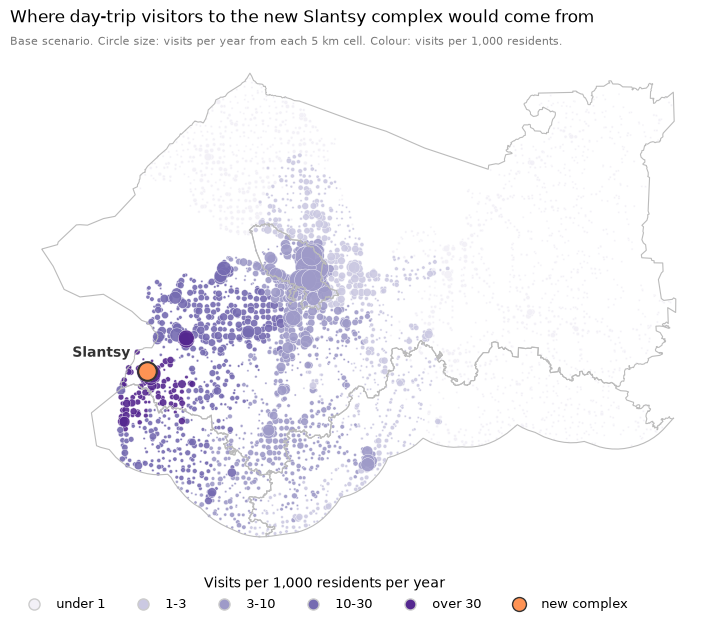

In [10]:
# catchment map
import geopandas as gpd
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D

area = gpd.read_file(f"{PROCESSED}/study_area.geojson").to_crs("EPSG:32636")
geo = pd.read_csv(f"{PROCESSED}/attractions_geo.csv").set_index("name_en")
pt = gpd.GeoSeries(gpd.points_from_xy([geo.loc[NEW_SITE_PROXY, "lon"]],
                                      [geo.loc[NEW_SITE_PROXY, "lat"]]),
                   crs="EPSG:4326").to_crs("EPSG:32636").iloc[0]

BINS = [0, 1, 3, 10, 30, np.inf]
LABELS = ["under 1", "1-3", "3-10", "10-30", "over 30"]
COLORS = ["#f2f0f7", "#cbc9e2", "#9e9ac8", "#756bb1", "#54278f"]
d = catch.assign(cls=pd.cut(catch["per_1000"], BINS, labels=False, include_lowest=True))
d = d.sort_values("visits")   # big circles drawn last
sizes = 2 + 250 * np.sqrt(d["visits"] / d["visits"].max())

fig, ax = plt.subplots(figsize=(9, 9))
area.boundary.plot(ax=ax, color="#bbbbbb", lw=0.8)
ax.scatter(d["x"], d["y"], s=sizes, c=[COLORS[int(k)] for k in d["cls"]],
           edgecolor="white", linewidth=0.3, alpha=0.9)
ax.scatter(pt.x, pt.y, marker="o", s=180, color="#FF9354", edgecolor="#333333",
           linewidth=1.5, zorder=5)
ax.annotate("Slantsy", (pt.x, pt.y), xytext=(-12, 10), textcoords="offset points",
            ha="right", fontsize=10, fontweight="bold", color="#333333",
            path_effects=[pe.withStroke(linewidth=3, foreground="white")], zorder=6)

handles = [Line2D([], [], marker="o", ls="", markersize=8, markerfacecolor=col,
                  markeredgecolor="#cccccc", label=lab) for col, lab in zip(COLORS, LABELS)]
handles.append(Line2D([], [], marker="o", ls="", markersize=10, markerfacecolor="#FF9354",
                      markeredgecolor="#333333", label="new complex"))
ax.legend(handles=handles, title="Visits per 1,000 residents per year", loc="upper left",
          bbox_to_anchor=(0, -0.01), ncol=6, frameon=False, fontsize=9)
ax.set_title("Where day-trip visitors to the new Slantsy complex would come from", loc="left", pad=20)
ax.text(0, 1.005, "Base scenario. Circle size: visits per year from each 5 km cell. "
        "Colour: visits per 1,000 residents.", transform=ax.transAxes, fontsize=8,
        color="#777777", va="bottom")
ax.set_aspect("equal")
ax.set_axis_off()
fig.savefig("../figures/06_catchment.png", dpi=200, bbox_inches="tight")
plt.show()